In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import re
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/competitions/playground-series-s4e9/sample_submission.csv
/kaggle/input/competitions/playground-series-s4e9/train.csv
/kaggle/input/competitions/playground-series-s4e9/test.csv


In [2]:
test = pd.read_csv('/kaggle/input/competitions/playground-series-s4e9/test.csv', index_col='id')
display(test.head())
display(test.describe())
test.info()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title
id,,,,,,,,,,,
188533,Land,Rover LR2 Base,2015,98000,Gasoline,240.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,6-Speed A/T,White,Beige,None reported,Yes
188534,Land,Rover Defender SE,2020,9142,Hybrid,395.0HP 3.0L Straight 6 Cylinder Engine Gasoli...,8-Speed A/T,Silver,Black,None reported,Yes
188535,Ford,Expedition Limited,2022,28121,Gasoline,3.5L V6 24V PDI DOHC Twin Turbo,10-Speed Automatic,White,Ebony,None reported,NaN
188536,Audi,A6 2.0T Sport,2016,61258,Gasoline,2.0 Liter TFSI,Automatic,Silician Yellow,Black,None reported,NaN
188537,Audi,A6 2.0T Premium Plus,2018,59000,Gasoline,252.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,A/T,Gray,Black,None reported,Yes


,model_year,milage
count,125690.000000,125690.000000
mean,2015.797526,66042.581510
std,5.673797,50223.858435
min,1974.000000,100.000000
25%,2013.000000,24500.000000
50%,2017.000000,57500.000000
75%,2020.000000,95798.000000
max,2024.000000,405000.000000


<class 'pandas.core.frame.DataFrame'>
Index: 125690 entries, 188533 to 314222
Data columns (total 11 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   brand         125690 non-null  object
 1   model         125690 non-null  object
 2   model_year    125690 non-null  int64 
 3   milage        125690 non-null  int64 
 4   fuel_type     122307 non-null  object
 5   engine        125690 non-null  object
 6   transmission  125690 non-null  object
 7   ext_col       125690 non-null  object
 8   int_col       125690 non-null  object
 9   accident      124058 non-null  object
 10  clean_title   111451 non-null  object
dtypes: int64(2), object(9)
memory usage: 11.5+ MB


In [3]:
train = pd.read_csv('/kaggle/input/competitions/playground-series-s4e9/train.csv', index_col='id')
display(train.head())
display(train.describe())
train.info()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
id,,,,,,,,,,,,
0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200
1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999
2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,None reported,Yes,13900
3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000
4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,None reported,Yes,97500


,model_year,milage,price
count,188533.000000,188533.000000,1.885330e+05
mean,2015.829998,65705.295174,4.387802e+04
std,5.660967,49798.158076,7.881952e+04
min,1974.000000,100.000000,2.000000e+03
25%,2013.000000,24115.000000,1.700000e+04
50%,2017.000000,57785.000000,3.082500e+04
75%,2020.000000,95400.000000,4.990000e+04
max,2024.000000,405000.000000,2.954083e+06


<class 'pandas.core.frame.DataFrame'>
Index: 188533 entries, 0 to 188532
Data columns (total 12 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   brand         188533 non-null  object
 1   model         188533 non-null  object
 2   model_year    188533 non-null  int64 
 3   milage        188533 non-null  int64 
 4   fuel_type     183450 non-null  object
 5   engine        188533 non-null  object
 6   transmission  188533 non-null  object
 7   ext_col       188533 non-null  object
 8   int_col       188533 non-null  object
 9   accident      186081 non-null  object
 10  clean_title   167114 non-null  object
 11  price         188533 non-null  int64 
dtypes: int64(3), object(9)
memory usage: 18.7+ MB


In [4]:
cols_to_lower = ['brand', 'model', 'engine', 'fuel_type', 'transmission']

for col in cols_to_lower:
    train[col] = train[col].str.lower().str.strip()
    test[col] = test[col].str.lower().str.strip()

In [5]:
brands_to_exclude = ['smart', 'polestar']
rows_to_drop = train[train['brand'].isin(brands_to_exclude)].index
train = train.drop(rows_to_drop)

In [6]:
fuel_pattern = r'(gasoline|diesel|e85 flex fuel|flex fuel|electric|hybrid|plug-in hybrid)'

for df in [train, test]:
    df['fuel_type'] = df['fuel_type'].replace(['–', 'not supported'], np.nan)
    extracted = df['engine'].str.extract(fuel_pattern, expand=False, flags=re.IGNORECASE)
    df['fuel_type'] = df['fuel_type'].fillna(extracted)

for df in [train, test]:
    df['fuel_type'] = df['fuel_type'].replace('e85 flex fuel', 'flex fuel')

In [7]:
train['clean_title'] = (train['clean_title'] == 'Yes').astype(int)
test['clean_title'] = (test['clean_title'] == 'Yes').astype(int)

In [8]:
accident_map = {
    'At least 1 accident or damage reported': 1,
    'None reported': 0
}

train['accident'] = train['accident'].map(accident_map).fillna(0).astype(int)
test['accident'] = test['accident'].map(accident_map).fillna(0).astype(int)

In [9]:
train['age'] = 2026 - train['model_year']
train = train.drop('model_year', axis=1)
test['age'] = 2026 - test['model_year']
test = test.drop('model_year', axis=1)

In [10]:
train = train.drop(columns=['ext_col', 'int_col'])
test = test.drop(columns=['ext_col', 'int_col'])

In [11]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

for df in [train, test]:
    df['hp'] = df['engine'].str.extract(r'(\d+\.?\d*)hp', flags=re.IGNORECASE).astype(float)
    df['liters'] = df['engine'].str.extract(r'(\d+\.?\d*)l', flags=re.IGNORECASE).astype(float)
    df['cylinder'] = df['engine'].str.extract(r'(\d+\.?\d*) cylinder', flags=re.IGNORECASE).astype(float)

cols_to_impute = ['hp', 'liters', 'cylinder', 'milage', 'age']

ii_imputer = IterativeImputer(
    max_iter=10, 
    random_state=42, 
    initial_strategy='median'
)

train[cols_to_impute] = ii_imputer.fit_transform(train[cols_to_impute])
test[cols_to_impute] = ii_imputer.transform(test[cols_to_impute])

In [12]:
X, y = train.drop('price', axis=1), train['price']

cat_cols = X.select_dtypes(include=['object']).columns
num_cols = X.select_dtypes(exclude=['object']).columns

median = X[num_cols].median()

X[num_cols] = X[num_cols].fillna(median)
test[num_cols] = test[num_cols].fillna(median)

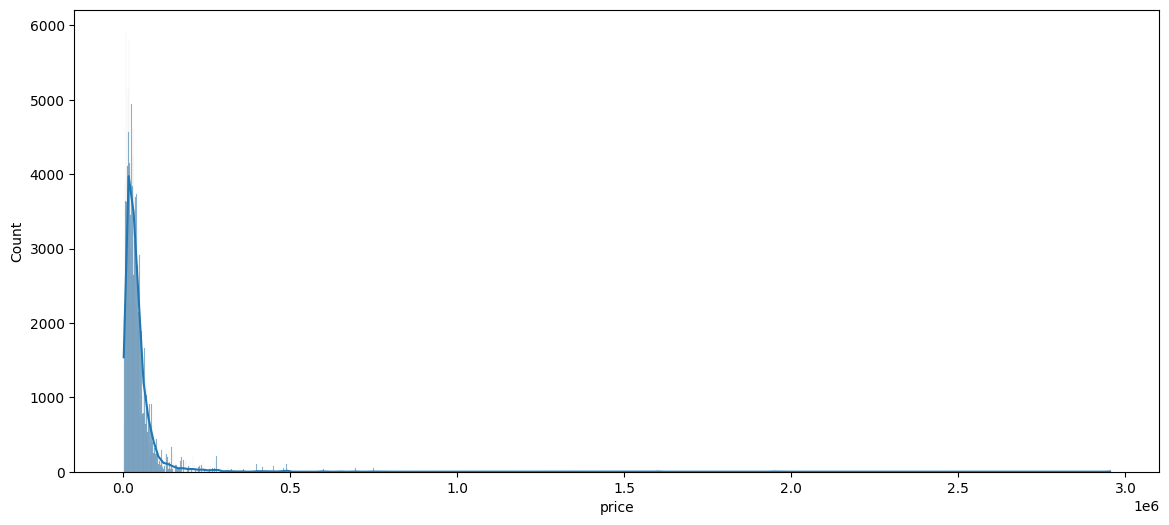

In [13]:
plt.figure(figsize=(14, 6))
sns.histplot(y, kde=True)
plt.show()

In [14]:
y = np.log1p(y)

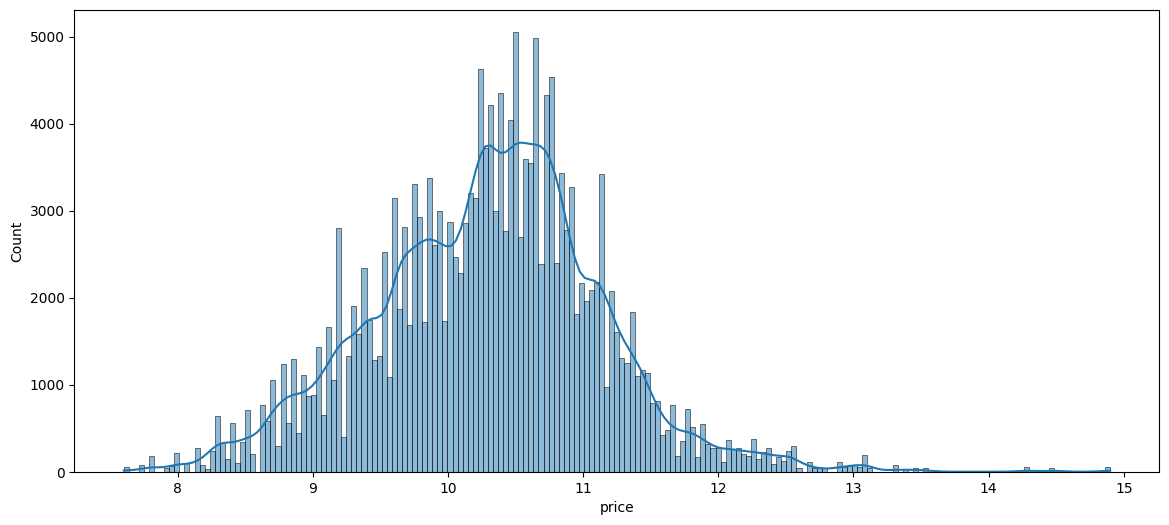

In [15]:
plt.figure(figsize=(14, 6))
sns.histplot(y, kde=True)
plt.show()

In [16]:
global_mean = y.mean()

for col in cat_cols:
    temp = pd.concat([X[col], y], axis=1)
    means = temp.groupby(col)['price'].mean()

    X[col] = X[col].map(means)
    test[col] = test[col].map(means)

In [17]:
features_to_log = ['milage', 'hp']

for col in features_to_log:
    X[col] = np.log1p(X[col])
    test[col] = np.log1p(test[col])

In [18]:
display(X.head())

,brand,model,milage,fuel_type,engine,transmission,accident,clean_title,age,hp,liters,cylinder
id,,,,,,,,,,,,
0,9.499797,9.281452,12.269052,10.270471,9.180990,9.962130,0,1,19.0,5.153292,1.6,4.0
1,10.034850,9.287142,11.872354,10.270471,9.257967,9.962130,1,1,24.0,5.533389,3.9,8.0
2,10.276437,9.889445,11.825778,9.918632,9.627235,9.962130,0,1,24.0,5.771441,5.3,8.0
3,10.596736,10.578328,9.878221,10.270471,10.479454,10.485864,0,1,9.0,6.042633,5.0,8.0
4,10.480668,10.763918,8.907748,10.270471,10.269279,10.430778,0,1,5.0,5.342334,2.0,4.0


In [19]:
display(test.head())

,brand,model,milage,fuel_type,engine,transmission,accident,clean_title,age,hp,liters,cylinder
id,,,,,,,,,,,,
188533,10.530090,9.643385,11.492733,10.270471,9.793050,9.912453,0,1,11.0,5.484797,2.000000,4.000000
188534,10.530090,11.057736,9.120744,10.671941,11.022152,10.671403,0,1,6.0,5.981414,3.000000,6.000000
188535,10.285060,10.663843,10.244307,10.270471,10.689900,10.784530,0,0,4.0,5.959520,3.500000,6.100899
188536,10.307215,10.183187,11.022866,10.270471,10.622315,10.784292,0,0,10.0,5.823943,3.553359,6.116206
188537,10.307215,10.033458,10.985310,10.270471,10.217261,9.962130,0,1,8.0,5.533389,2.000000,4.000000


In [20]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

In [21]:
model = lgb.LGBMRegressor(
    max_depth=10,
    learning_rate=0.008,
    n_estimators=8000,
    min_child_samples=50,
    random_state=42,
    importance_type='gain',
    verbosity=-1
)

In [22]:
model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    eval_metric='mae',
    callbacks=[
        lgb.early_stopping(stopping_rounds=50),
        lgb.log_evaluation(period=250)
    ]
)

Training until validation scores don't improve for 50 rounds
[250]	valid_0's l1: 0.357558	valid_0's l2: 0.260059
[500]	valid_0's l1: 0.34687	valid_0's l2: 0.244922
[750]	valid_0's l1: 0.345193	valid_0's l2: 0.242427
[1000]	valid_0's l1: 0.34441	valid_0's l2: 0.241379
[1250]	valid_0's l1: 0.343957	valid_0's l2: 0.240757
[1500]	valid_0's l1: 0.343602	valid_0's l2: 0.240285
[1750]	valid_0's l1: 0.343319	valid_0's l2: 0.239942
[2000]	valid_0's l1: 0.343041	valid_0's l2: 0.239629
[2250]	valid_0's l1: 0.342778	valid_0's l2: 0.239308
[2500]	valid_0's l1: 0.342565	valid_0's l2: 0.23909
[2750]	valid_0's l1: 0.342411	valid_0's l2: 0.238934
[3000]	valid_0's l1: 0.342275	valid_0's l2: 0.238814
[3250]	valid_0's l1: 0.342103	valid_0's l2: 0.23866
[3500]	valid_0's l1: 0.341961	valid_0's l2: 0.238565
Early stopping, best iteration is:
[3536]	valid_0's l1: 0.341951	valid_0's l2: 0.23856


LGBMRegressor(importance_type='gain', learning_rate=0.008, max_depth=10,
              min_child_samples=50, n_estimators=8000, random_state=42,
              verbosity=-1)

In [23]:
val_preds = np.expm1(model.predict(X_val))
mae = mean_absolute_error(np.expm1(y_val), val_preds)
print(f"MAE: {mae:,.0f}")

MAE: 17,374


In [24]:
best_iter = model.best_iteration_

In [25]:
model = lgb.LGBMRegressor(
    max_depth=10,
    learning_rate=0.008,
    n_estimators=int(best_iter * 1.15),
    min_child_samples=50,
    random_state=42,
    importance_type='gain',
    verbosity=-1
)

model.fit(X, y)

LGBMRegressor(importance_type='gain', learning_rate=0.008, max_depth=10,
              min_child_samples=50, n_estimators=4066, random_state=42,
              verbosity=-1)

In [26]:
preds = np.expm1(model.predict(test))

In [27]:
submission = pd.DataFrame({
    'id': test.index,
    'price': preds
})
submission.to_csv('submission.csv', index=False)